# House Price Prediction (Ames, Iowa)

**Business question:** what makes a house valuable, and how accurately can we estimate its sale price from its features?
Rebuilt from my Digital Skola *Maestro Project* (regression and feature engineering).

**Data:** 1,460 homes sold in Ames, Iowa, 2006–2010, with 79 features (`data/house_prices_train.csv.gz`), plus
1,459 homes without prices to predict (`data/house_prices_test.csv.gz`). This is the public Kaggle *House Prices* dataset.
Metric: RMSE on the log of the price, so errors on cheap and expensive houses count equally.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
train = pd.read_csv("data/house_prices_train.csv.gz")
test = pd.read_csv("data/house_prices_test.csv.gz")
print("train", train.shape, "| test", test.shape)

train (1460, 81) | test (1459, 80)


## 1. The target: sale price

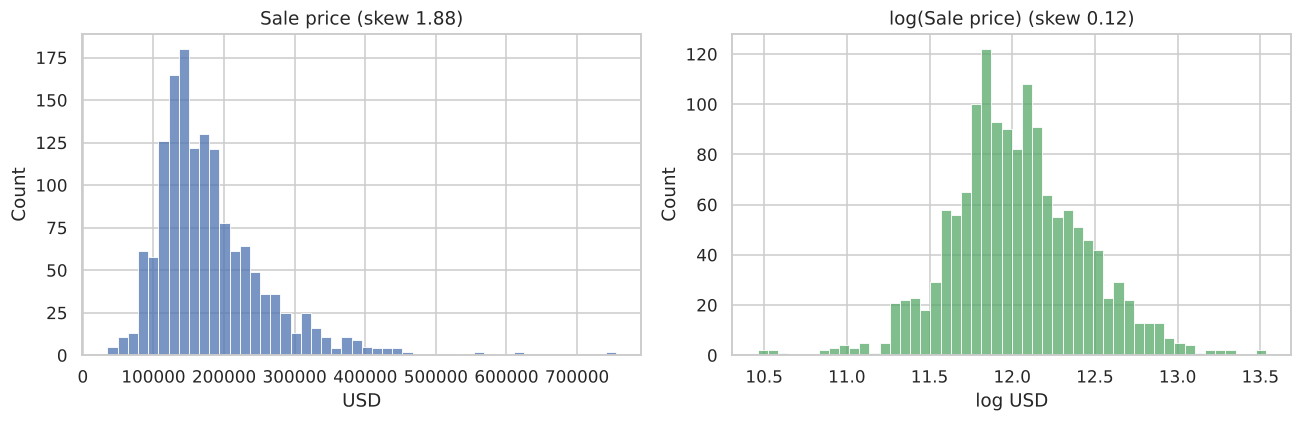

,SalePrice
count,1460.0
mean,180921.0
std,79443.0
min,34900.0
25%,129975.0
50%,163000.0
75%,214000.0
max,755000.0


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["SalePrice"], bins=50, ax=axes[0], color="#4C72B0")
axes[0].set(title=f"Sale price (skew {train['SalePrice'].skew():.2f})", xlabel="USD")
sns.histplot(np.log1p(train["SalePrice"]), bins=50, ax=axes[1], color="#55A868")
axes[1].set(title=f"log(Sale price) (skew {np.log1p(train['SalePrice']).skew():.2f})", xlabel="log USD")
plt.tight_layout()
train["SalePrice"].describe().round(0)

Prices are right-skewed (a few very expensive homes), so models are trained on log(price). This also matches the evaluation metric.

## 2. What drives price?

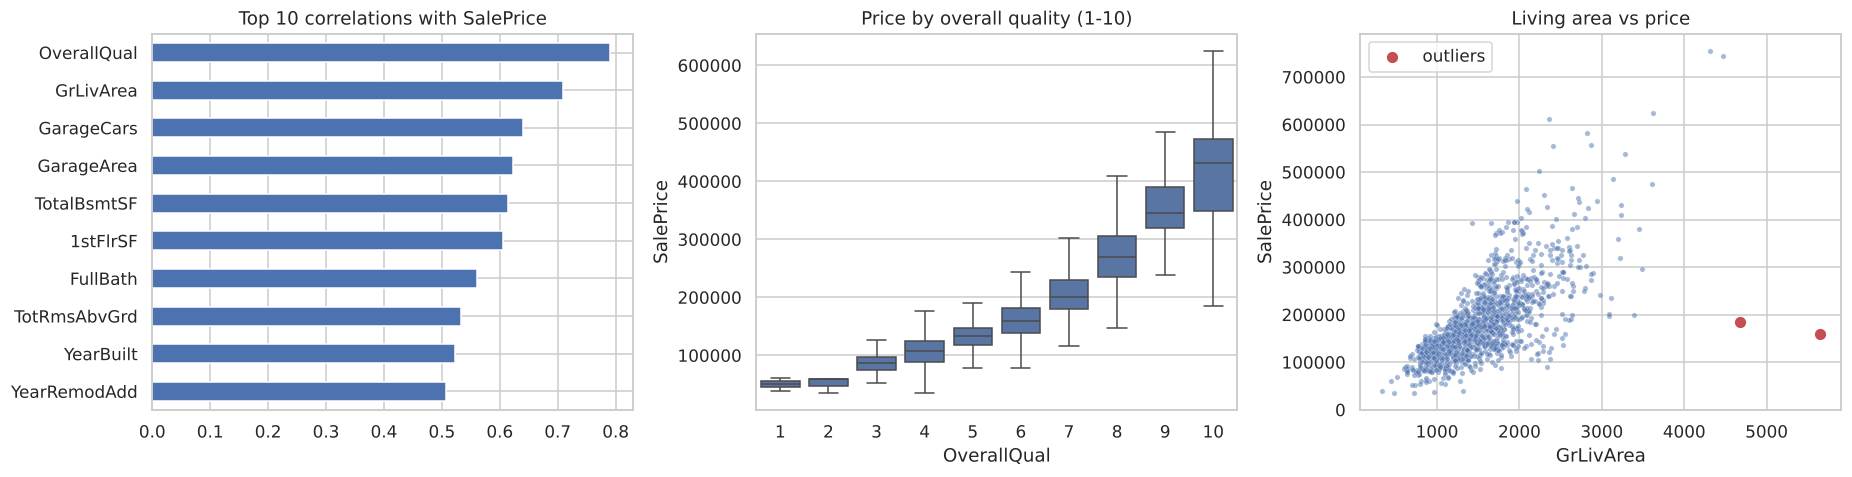

,SalePrice
OverallQual,0.79
GrLivArea,0.71
GarageCars,0.64
GarageArea,0.62
TotalBsmtSF,0.61
1stFlrSF,0.61
FullBath,0.56
TotRmsAbvGrd,0.53
YearBuilt,0.52
YearRemodAdd,0.51


In [3]:
num = train.select_dtypes("number").drop(columns=["Id"])
corr = num.corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
corr.head(10).sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set(title="Top 10 correlations with SalePrice")
sns.boxplot(data=train, x="OverallQual", y="SalePrice", ax=axes[1], color="#4C72B0", showfliers=False)
axes[1].set(title="Price by overall quality (1-10)")
sns.scatterplot(data=train, x="GrLivArea", y="SalePrice", ax=axes[2], s=12, alpha=0.5)
out = train[(train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)]
axes[2].scatter(out["GrLivArea"], out["SalePrice"], color="#C44E52", s=40, label="outliers")
axes[2].set(title="Living area vs price"); axes[2].legend()
plt.tight_layout()
corr.head(10).round(2)

In [4]:
nb_price = train.groupby("Neighborhood")["SalePrice"].median().sort_values()
print(f"Cheapest neighbourhood median: ${nb_price.iloc[0]:,.0f} ({nb_price.index[0]})")
print(f"Most expensive neighbourhood median: ${nb_price.iloc[-1]:,.0f} ({nb_price.index[-1]})")
q = train.groupby("OverallQual")["SalePrice"].median()
print(f"Median price at quality 5: ${q[5]:,.0f} vs quality 8: ${q[8]:,.0f}")

Cheapest neighbourhood median: $88,000 (MeadowV)
Most expensive neighbourhood median: $315,000 (NridgHt)
Median price at quality 5: $133,000 vs quality 8: $269,750


**Findings:** overall quality and living area are the strongest drivers, followed by garage size, basement size and age.
Location matters too: the median price in the most expensive neighbourhood is several times that of the cheapest.
Two very large homes (over 4,000 sq ft) sold far below the trend, likely partial sales. They are removed so they do not distort the model.

## 3. Clean data and engineer features

In [5]:
train = train.drop(out.index)
y = np.log1p(train["SalePrice"])
full = pd.concat([train.drop(columns=["SalePrice"]), test], keys=["train", "test"])

# 'NA' in these columns means the house has no such feature, not missing data
none_cols = ["Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond", "PoolQC", "Fence", "MiscFeature", "MasVnrType"]
full[none_cols] = full[none_cols].fillna("None")
for c in ["GarageArea", "GarageCars", "TotalBsmtSF", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF",
          "BsmtFullBath", "BsmtHalfBath", "MasVnrArea"]:
    full[c] = full[c].fillna(0)
full["LotFrontage"] = full.groupby("Neighborhood")["LotFrontage"].transform(lambda s: s.fillna(s.median()))

# New features
full["TotalSF"] = full["TotalBsmtSF"] + full["1stFlrSF"] + full["2ndFlrSF"]
full["TotalBaths"] = full["FullBath"] + 0.5 * full["HalfBath"] + full["BsmtFullBath"] + 0.5 * full["BsmtHalfBath"]
full["HouseAge"] = full["YrSold"] - full["YearBuilt"]
full["YearsSinceRemodel"] = full["YrSold"] - full["YearRemodAdd"]
full["TotalPorchSF"] = full[["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch", "WoodDeckSF"]].sum(axis=1)
full["MSSubClass"] = full["MSSubClass"].astype(str)
full = full.drop(columns=["Id", "Utilities", "Street", "PoolQC"])

X, X_test = full.loc["train"], full.loc["test"]
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes("number").columns.tolist()
print(f"{len(num_cols)} numeric + {len(cat_cols)} categorical features | rows: {len(X)}")
print("New feature correlation with log price:",
      X.assign(y=y.values)[["TotalSF", "TotalBaths", "HouseAge", "y"]].corr()["y"].drop("y").round(2).to_dict())

40 numeric + 41 categorical features | rows: 1458
New feature correlation with log price: {'TotalSF': 0.83, 'TotalBaths': 0.68, 'HouseAge': -0.59}


## 4. Compare models (5-fold cross-validated RMSE on log price)

In [6]:
linear_prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=5))]), cat_cols)])
tree_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False))]), cat_cols)])

# skewed numeric features are log-transformed for the linear models
skewed = [c for c in num_cols if X[c].min() >= 0 and abs(X[c].skew()) > 0.75]
def log_skewed(df):
    df = df.copy(); df[skewed] = np.log1p(df[skewed]); return df
X_lin, X_test_lin = log_skewed(X), log_skewed(X_test)

models = {
    "Ridge": (Pipeline([("prep", linear_prep), ("m", RidgeCV(alphas=np.logspace(-1, 3, 30)))]), X_lin),
    "Lasso": (Pipeline([("prep", linear_prep), ("m", LassoCV(alphas=np.logspace(-4, -1, 30), max_iter=50000, random_state=RANDOM_STATE))]), X_lin),
    "Random Forest": (Pipeline([("prep", tree_prep), ("m", RandomForestRegressor(n_estimators=400, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE))]), X),
    "Gradient Boosting": (Pipeline([("prep", tree_prep), ("m", HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=RANDOM_STATE))]), X),
}
cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
scores = {}
for name, (pipe, data) in models.items():
    rmse = -cross_val_score(pipe, data, y, cv=cv, scoring="neg_root_mean_squared_error")
    scores[name] = {"CV RMSE (log)": rmse.mean(), "std": rmse.std(),
                    "approx. % error": (np.exp(rmse.mean()) - 1) * 100}
results = pd.DataFrame(scores).T.sort_values("CV RMSE (log)").round(4)
results

,CV RMSE (log),std,approx. % error
Lasso,0.1102,0.0073,11.6549
Ridge,0.1129,0.0081,11.9477
Gradient Boosting,0.1236,0.0076,13.1513
Random Forest,0.1357,0.0072,14.5381


In [7]:
# Blend: average of the best linear model and gradient boosting
from sklearn.model_selection import cross_val_predict
p_lasso = cross_val_predict(models["Lasso"][0], X_lin, y, cv=cv)
p_gb = cross_val_predict(models["Gradient Boosting"][0], X, y, cv=cv)
blend_rmse = np.sqrt(np.mean((0.5 * p_lasso + 0.5 * p_gb - y) ** 2))
print(f"Blend (50% Lasso + 50% Gradient Boosting) CV RMSE: {blend_rmse:.4f} "
      f"(~{(np.exp(blend_rmse) - 1) * 100:.1f}% typical error)")

Blend (50% Lasso + 50% Gradient Boosting) CV RMSE: 0.1110 (~11.7% typical error)


## 5. Final model and test-set predictions

count      1459.0
mean     178848.0
std       78483.0
min       42620.0
25%      126824.0
50%      158221.0
75%      210466.0
max      894598.0
Lasso kept 105 of 290 features


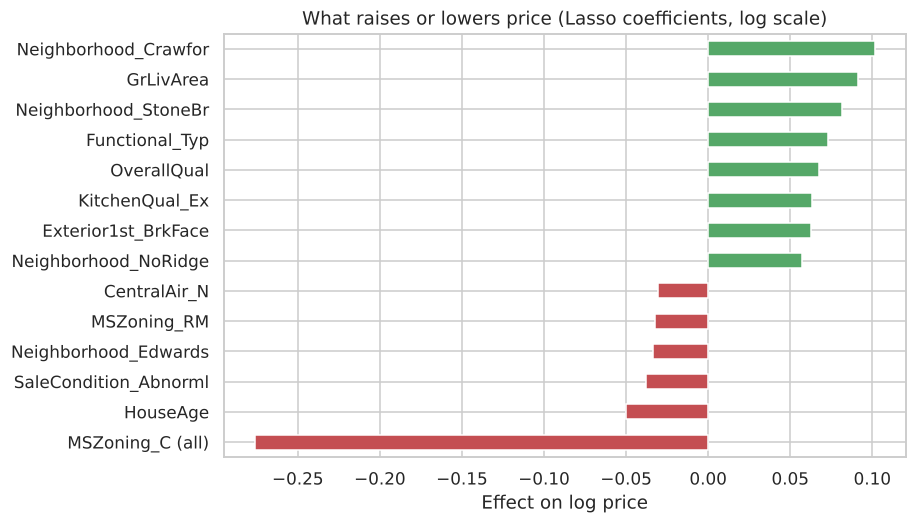

In [8]:
lasso = models["Lasso"][0].fit(X_lin, y)
pred = np.expm1(lasso.predict(X_test_lin))   # Lasso alone scored best in cross-validation
submission = pd.DataFrame({"Id": test["Id"], "SalePrice": pred.round(0)})
submission.to_csv("data/house_prices_predictions.csv", index=False)
print(submission["SalePrice"].describe().round(0).to_string())

coef = pd.Series(lasso.named_steps["m"].coef_, index=lasso.named_steps["prep"].get_feature_names_out())
coef.index = coef.index.str.replace("num__", "").str.replace("cat__", "")
top = pd.concat([coef.nlargest(8), coef.nsmallest(6)]).sort_values()
ax = top.plot(kind="barh", figsize=(8, 5), color=["#C44E52" if v < 0 else "#55A868" for v in top])
ax.set(title="What raises or lowers price (Lasso coefficients, log scale)", xlabel="Effect on log price")
print("Lasso kept", (coef != 0).sum(), "of", len(coef), "features")

## 6. Conclusions

* **Quality and size set the price.** Overall quality, total square footage and living area are the strongest drivers, followed by location (neighbourhood), age and garage.
* **Feature engineering helped.** Total square footage (r = 0.83 with log price) and total bathrooms (r = 0.68) combine several weaker columns into stronger signals.
* **Accuracy:** Lasso regression on log price has the lowest cross-validated error (RMSE 0.110, about 11.7% typical error). Blending it with gradient boosting did not improve the score, so the simpler model is used. It keeps 105 of 290 encoded features, and test-set predictions are saved in `data/house_prices_predictions.csv`.
* **Use case:** a fast first valuation for agents or buyers, and a check on listing prices that look too high or too low. It does not replace an appraisal, because the data covers one US city in 2006–2010.